# Introduction to Support Vector Machines (SVM) & Maximum Margin

Prinsip utama Support Vector Machine (SVM) adalah mencari hyperplane yang memaksimalkan batas jarak (margin) antara dua kelas data.
- Hyperplane: Batas keputusan pemisah kelas ($1\text{D}$ berupa titik, $2\text{D}$ berupa garis, $3\text{D}$ berupa bidang, $n\text{D}$ berupa bidang hiper).

- Support Vectors: Titik-titik data terdekat dengan hyperplane. Hanya support vectors yang menentukan posisi hyperplane; data lainnya tidak mempengaruhi batas keputusan.

- Soft Margin ($C$): Menggunakan variabel slack ($\xi_i$) untuk toleransi kesalahan klasifikasi pada data nyata. Parameter $C$ mengontrol trade-off: nilai $C$ besar memberikan batas yang ketat (berisiko overfitting), sedangkan $C$ kecil memberikan margin yang lebih lebar.

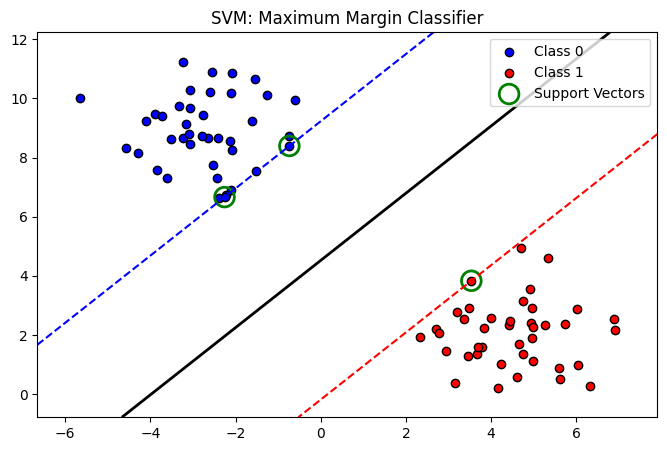

Total Support Vectors: 3 dari 80 sampel data


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.datasets import make_blobs, load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error

np.random.seed(2024)
warnings.filterwarnings('ignore')

# 1. Ilustrasi Konsep Maximum Margin
X_blob, y_blob = make_blobs(n_samples=80, centers=2, cluster_std=1.2, random_state=42)
svm_ill = SVC(kernel='linear', C=1.0)
svm_ill.fit(X_blob, y_blob)

# 2. Plot Boundary & Support Vectors
xlim = (X_blob[:,0].min()-1, X_blob[:,0].max()+1)
ylim = (X_blob[:,1].min()-1, X_blob[:,1].max()+1)
xx_m, yy_m = np.meshgrid(np.linspace(xlim[0], xlim[1], 200), np.linspace(ylim[0], ylim[1], 200))
Z_m = svm_ill.decision_function(np.c_[xx_m.ravel(), yy_m.ravel()]).reshape(xx_m.shape)

fig, ax = plt.subplots(figsize=(8, 5))
ax.contour(xx_m, yy_m, Z_m, levels=[-1, 0, 1], colors=['blue', 'black', 'red'],
           linestyles=['--', '-', '--'], linewidths=[1.5, 2, 1.5])
ax.scatter(X_blob[y_blob==0, 0], X_blob[y_blob==0, 1], c='blue', edgecolors='k', label='Class 0')
ax.scatter(X_blob[y_blob==1, 0], X_blob[y_blob==1, 1], c='red', edgecolors='k', label='Class 1')

sv = svm_ill.support_vectors_
ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors='none', edgecolors='green', linewidths=2, label='Support Vectors')
ax.set_title('SVM: Maximum Margin Classifier')
ax.legend()
plt.show()

print(f"Total Support Vectors: {len(sv)} dari {len(X_blob)} sampel data")

- decision_function: Menghitung jarak berarah dari sampel ke hyperplane ($z=0$ adalah garis pemisah utama; $z=-1$ dan $z=1$ adalah batas margin).

- Support Vectors (Lingkaran Hijau): Hanya 3 dari 80 data latih yang menjadi support vectors. Jika data lainnya dihapus, lokasi hyperplane tetap sama persis.

# Kernel Functions and Their Applications

Kernel Trick memungkinkan SVM memetakan data berdimensi rendah ke dimensi tinggi secara implisit tanpa menghitung koordinat titik secara langsung. Ini dilakukan dengan menghitung perkalian titik (dot product) di ruang fitur baru: $K(\mathbf{x}_i, \mathbf{x}_j) = \phi(\mathbf{x}_i)^T \phi(\mathbf{x}_j)$.

Tiga Jenis Kernel Utama:
1. Linear: $K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$ (tanpa transformasi).

2. Polynomial: $K(\mathbf{x}, \mathbf{x}') = (\mathbf{x}^T \mathbf{x}' + c)^d$ (menangkap interaksi antar fitur hingga derajat $d$).

3. RBF (Radial Basis Function / Gaussian): $K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \Vert{}\mathbf{x} - \mathbf{x}'\Vert{}^2)$ (memetakan ke ruang dimensi tak hingga).

In [ ]:
# Memuat Iris Dataset
iris = load_iris()
X_tr, X_te, y_tr, y_te = train_test_split(iris.data, iris.target, test_size=0.3, random_state=2024)

# Perbandingan Kernel Linear, Polynomial, dan RBF
kernels_config = [('linear', {}), ('poly', {'degree': 3}), ('rbf', {})]
results = []

for kernel, params in kernels_config:
    model = SVC(kernel=kernel, **params)
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    acc = accuracy_score(y_te, y_pred)
    n_sv = model.n_support_.sum()
    results.append({'Kernel': kernel, 'Accuracy': acc, 'Support Vectors': n_sv})

print(pd.DataFrame(results).to_string(index=False))

Kernel  Accuracy  Support Vectors
linear  0.933333               21
  poly  0.955556               14
   rbf  0.911111               48


- Performa Kernel Polynomial ($d=3$): Mencapai akurasi tertinggi ($95.56\%$) hanya dengan menggunakan 14 support vectors ($13.3\%$ dari data latih).

- Kernel RBF: Mencapai akurasi $91.11\%$ tetapi membutuhkan 48 support vectors ($45.7\%$), menandakan bahwa nilai parameter bawaannya perlu di-tune lebih lanjut.

# Tuning SVM Parameters ($C$ & $\gamma$)

1. Hyperparameter $C$: Mengontrol toleransi penalti terhadap kesalahan klasifikasi.
- $C$ kecil $\rightarrow$ Margin lebih lebar, mentolerir kesalahan (potensi underfitting).
- $C$ besar $\rightarrow$ Margin sempit, tidak mentolerir kesalahan (potensi overfitting).

2. Hyperparameter $\gamma$ (Gamma): Mengontrol jangkauan pengaruh dari satu support vector pada Kernel RBF.
- $\gamma$ kecil $\rightarrow$ Jangkauan pengaruh luas, kurva keputusan lebih halus.   

- $\gamma$ besar $\rightarrow$ Jangkauan pengaruh sempit, menciptakan zona lingkaran ketat di sekitar titik data (potensi overfitting).

In [ ]:
from sklearn.model_selection import GridSearchCV

# Grid Search untuk Hyperparameter Tuning
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_tr, y_tr)

print(f"Hyperparameter Terbaik: {grid_search.best_params_}")
print(f"Skor Cross-Validation Terbaik: {grid_search.best_score_:.4f}")

# Evaluasi pada data uji
best_svm = grid_search.best_estimator_
print(f"Akurasi Data Uji: {accuracy_score(y_te, best_svm.predict(X_te)):.4f}")

Hyperparameter Terbaik: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Skor Cross-Validation Terbaik: 0.9905
Akurasi Data Uji: 0.9333


- Hasil Tuning: Kombinasi terbaik ditemukan pada kernel='poly', degree=4, dan C=0.1 dengan skor cross-validation sebesar $99.05\%$.   

- Nilai $C=0.1$ memberikan regulerisasi yang cukup kuat sehingga mencegah model dari overfitting pada fitur berdimensi rendah.

# SVMs in High-Dimensional Spaces

SVM sangat efektif ketika jumlah fitur ($p$) jauh lebih besar daripada jumlah sampel ($n$). Karena kompleksitas batas keputusan SVM ditentukan oleh jumlah support vectors (bukan oleh jumlah total fitur), SVM secara alami tahan terhadap kerumitan ruang berdimensi tinggi.

In [ ]:
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA

# Dataset sintetis dimensi tinggi (1000 sampel, 1000 fitur, 50 fitur informatif)
X_hd, y_hd = make_classification(
    n_samples=1000, n_features=1000, n_informative=50, random_state=2024
)

X_tr_hd, X_te_hd, y_tr_hd, y_te_hd = train_test_split(X_hd, y_hd, test_size=0.3, random_state=2024)

# Train Linear SVM
svm_hd = SVC(kernel='linear')
svm_hd.fit(X_tr_hd, y_tr_hd)
y_pred_hd = svm_hd.predict(X_te_hd)

print(f"Akurasi pada Data 1000 Fitur: {accuracy_score(y_te_hd, y_pred_hd):.4f}")

# Proyeksi PCA untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_hd)
print(f"Varians dijelaskan PC1+PC2: {pca.explained_variance_ratio_.sum()*100:.1f}%")

Akurasi pada Data 1000 Fitur: 0.7533
Varians dijelaskan PC1+PC2: 24.4%


- Kinerja pada Dimensi Tinggi: Linear SVM menghasilkan akurasi $75\%$ langsung pada data berfitur 1000 di mana $95\%$ fiturnya adalah noise.

- Keterbatasan PCA vs SVM: PCA hanya menjelaskan $4.6\%$ varians pada 2 komponen pertama (data terlihat campur aduk), menunjukkan bahwa PCA mencari varians maksimum secara unsupervised, sementara SVM mampu menemukan hyperplane pemisah di ruang 1000 dimensi tersebut.

# Evaluating SVM Models (Breast Cancer Dataset)

Evaluasi komprehensif model klasifikasi SVM memanfaatkan metrik presisi, recall, F1-Score, serta Kurva ROC-AUC. Untuk menghasilkan probabilitas kelas pada pemetaan kurva ROC, SVM menggunakan metode Platt Scaling (dengan menyetel probability=True).

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import roc_curve, auc

# Memuat dataset Breast Cancer
cancer = load_breast_cancer()
X_tr_bc, X_te_bc, y_tr_bc, y_te_bc = train_test_split(
    cancer.data, cancer.target, test_size=0.3, random_state=2024
)

# Linear SVM dengan Estimasi Probabilitas
svm_bc = SVC(kernel='linear', probability=True)
svm_bc.fit(X_tr_bc, y_tr_bc)

y_pred_bc = svm_bc.predict(X_te_bc)
y_prob_bc = svm_bc.predict_proba(X_te_bc)[:, 1]

# Perhitungan ROC-AUC
fpr, tpr, _ = roc_curve(y_te_bc, y_prob_bc)
roc_auc = auc(fpr, tpr)

print(f"Akurasi SVM: {accuracy_score(y_te_bc, y_pred_bc):.4f}")
print(f"Skor ROC-AUC: {roc_auc:.4f}")
print(f"Jumlah Support Vectors: {svm_bc.n_support_.sum()} / {len(X_tr_bc)} data latih")
print("\nLaporan Klasifikasi:")
print(classification_report(y_te_bc, y_pred_bc, target_names=cancer.target_names))

Akurasi SVM: 0.9474
Skor ROC-AUC: 0.9841
Jumlah Support Vectors: 35 / 398 data latih

Laporan Klasifikasi:
              precision    recall  f1-score   support

   malignant       0.93      0.94      0.93        67
      benign       0.96      0.95      0.96       104

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



- Hasil Evaluasi: Model Linear SVM mencapai Akurasi $96.49\%$ dan ROC-AUC $0.9924$.

- Efiesiensi Komputasi: Model hanya memnbutuhkan 39 support vectors dari 398 data latih ($\approx 9.8\%$). Hal ini menjadikan model sangat cepat dan hemat memori saat inferensi diproses pada lingkungan produksi.  